# Rejecting aerodynamic drag: incremental (INDI) vs cascaded PID control

A quadrotor in forward flight feels a drag force from its rotors that grows with airspeed. A
controller that doesn't model drag has to correct for it as it happens. This notebook flies the
same fast trajectories with two controllers, with drag switched on and off, and measures how
much drag changes each controller's tracking.

* **Cascaded PID.** Position error feeds a velocity loop, then an attitude loop, with velocity and
  acceleration feedforward from the reference. Drag is invisible to it until it builds up as a
  tracking error.
* **INDI (incremental nonlinear dynamic inversion).** The controller measures the acceleration
  the vehicle actually has (the accelerometer's specific force) and commands only the *increment*
  of thrust and attitude needed to reach the desired acceleration. An unmodelled force such as
  drag shows up directly in that measurement, so it is cancelled at the next control tick.

**Result.** Drag moves the PID-flown vehicle's tracking error by 0.24–0.35 m. It moves the INDI
vehicle's by 0.02–0.04 m, close to INDI's own run-to-run scatter. Measured in time, drag delays
the PID vehicle by 110–175 ms and the INDI vehicle by 4–12 ms.

## 1. The drag model and why it matters here

The simulator uses first-order linear rotor drag, written in the body frame:

$$\mathbf F_\text{drag} = -R\,D\,R^\top \mathbf v, \qquad D = \operatorname{diag}(0.35,\ 0.35,\ 0.15)\ \tfrac{\text{N}}{\text{m/s}}$$

where $R$ is the body attitude and $\mathbf v$ the velocity. The vehicle is a 1 kg quadrotor with
a 30 ms first-order motor lag. The two test trajectories both have an 8 s period:

* a **circle** of 2 m radius, and
* a **figure-eight** (Gerono lemniscate) of 2 m amplitude.

Each starts and ends at rest with a 3 s smooth ramp.

On the circle the drag is a large fraction of what the controller must produce. The force needed
to stay on the circle is $m v^2/r$, while drag opposes $\mathbf v$ along the track:

In [1]:
import json
from itertools import combinations
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from pymavlink import DFReader

MASS_KG, DRAG_XY = 1.0, 0.35
radius, period = 2.0, 8.0
speed = 2 * np.pi * radius / period
centripetal = MASS_KG * speed ** 2 / radius
drag = DRAG_XY * speed
print(f"speed {speed:.2f} m/s: centripetal force {centripetal:.2f} N, drag {drag:.2f} N "
      f"({100 * drag / centripetal:.0f}% of it), acting along the track")

speed 1.57 m/s: centripetal force 1.23 N, drag 0.55 N (45% of it), acting along the track


For a PID cascade, a steady along-track force like this ends up as a steady along-track *lag*.
The loop has to build a position or velocity error before it pushes back harder.

INDI works differently. The commanded increment is

$$\Delta \mathbf a_\text{cmd} = \mathbf a_\text{des} - \mathbf a_\text{meas},$$

so a drag force lowers $\mathbf a_\text{meas}$ and is answered within a control period, without
waiting for position error to accumulate. This is the claim tested below.

## 2. Experiment design

A 2 × 2 factorial design: {PID, INDI} × {drag off, drag on}, each condition flown **three
times**. Every run uses the same airframe, firmware, parameters, takeoff and pre-trajectory
hover. Then it flies the circle followed by the figure-eight. The PID runs never switch the INDI
controller on. The INDI runs switch it on after a settled hover.

For each run, the analysis uses two logged signals per trajectory:

* the **reference** as the vehicle received it, and
* the vehicle's **estimated position**, from its onboard navigation filter.

Both are logged on the vehicle's own clock, so latency on the link that delivers the reference
does not enter the comparison. The simulator's true position is logged too, and is used in
section 6.

In [2]:
DATA = Path("/data/andrew/dev/drone/data/drag-ab-run/repeats")
CONTROLLERS = {"PID": "stock", "INDI": "custom"}
DRAG = {"drag off": "false", "drag on": "true"}
CASE_LABELS = {"circle_fast": "circle", "lemniscate_fast": "figure-eight"}
RUNS = (1, 2, 3)

# Categorical slots 1-2 (validated light-mode pair): colour = controller, line style = drag.
COLORS = {"PID": "#2a78d6", "INDI": "#eb6834"}
STYLES = {"drag off": "--", "drag on": "-"}
REF_COLOR = "#8a8a85"
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})


def read_rows(log_path, kinds):
    # One pass over a flight log: {message: {field: array}}; TimeUS kept in microseconds.
    log = DFReader.DFReader_binary(str(log_path))
    rows = {k: [] for k in kinds}
    while (m := log.recv_match(type=list(kinds))) is not None:
        if m.get_type() == "XKF1" and m.C != 0:
            continue  # navigation-filter core 0 only
        rows[m.get_type()].append([getattr(m, f) for f in kinds[m.get_type()]])
    return {k: dict(zip(kinds[k], np.array(v, float).T)) for k, v in rows.items()}


def split_blocks(mask, min_len=50):
    edges = np.flatnonzero(np.diff(np.r_[0, mask.astype(int), 0]))
    return [(a, b) for a, b in zip(edges[::2], edges[1::2]) if b - a >= min_len]


def load_run(controller, drag, run):
    folder = DATA / f"{CONTROLLERS[controller]}-drag-{DRAG[drag]}-{run}"
    cases = [c["case"] for c in json.loads((folder / "indi_flatness_flown.json").read_text())]
    truth_fields = {"SIM2": ["TimeUS", "PN", "PE", "PD"]}
    out = {}
    if controller == "PID":
        # Position targets as received, and the navigation-filter position.
        d = read_rows(folder / "flight.BIN", {"GUIP": ["TimeUS", "pX", "pY", "pZ"],
                                              "XKF1": ["TimeUS", "PN", "PE", "PD"], **truth_fields})
        g, x = d["GUIP"], d["XKF1"]
        bursts = np.split(np.arange(len(g["TimeUS"])),
                          np.flatnonzero(np.diff(g["TimeUS"]) > 1e6) + 1)[-len(cases):]
        for case, idx in zip(cases, bursts):
            out[case] = {"ref_t": g["TimeUS"][idx],
                         "ref": np.column_stack([g["pX"][idx], g["pY"][idx], g["pZ"][idx]]),
                         "pos_t": x["TimeUS"], "pos": np.column_stack([x["PN"], x["PE"], x["PD"]])}
    else:
        # INDI outer-loop log: received reference and estimated position on the same tick,
        # with a flag that is 0 while the reference is live.
        d = read_rows(folder / "flight.BIN", {"INDB": ["TimeUS", "RPx", "RPy", "RPz",
                                                       "Px", "Py", "Pz", "FB"], **truth_fields})
        b = d["INDB"]
        for case, (i, j) in zip(cases, split_blocks(b["FB"] == 0)):
            t = b["TimeUS"][i:j]
            out[case] = {"ref_t": t, "ref": np.column_stack([b["RPx"], b["RPy"], b["RPz"]])[i:j],
                         "pos_t": t, "pos": np.column_stack([b["Px"], b["Py"], b["Pz"]])[i:j]}
    s = d["SIM2"]
    for case in out.values():
        case["truth_t"], case["truth"] = s["TimeUS"], np.column_stack([s["PN"], s["PE"], s["PD"]])
    return out


runs = {(c, dr, k): load_run(c, dr, k) for c in CONTROLLERS for dr in DRAG for k in RUNS}
print(f"loaded {len(runs)} runs; samples per case (reference):")
for key, r in runs.items():
    print(f"  {key[0]:4s} {key[1]:8s} run {key[2]}: " +
          ", ".join(f"{CASE_LABELS[c]} {len(v['ref_t'])}" for c, v in r.items()))

loaded 12 runs; samples per case (reference):
  PID  drag off run 1: circle 950, figure-eight 950
  PID  drag off run 2: circle 950, figure-eight 950
  PID  drag off run 3: circle 950, figure-eight 950
  PID  drag on  run 1: circle 950, figure-eight 950
  PID  drag on  run 2: circle 950, figure-eight 950
  PID  drag on  run 3: circle 950, figure-eight 950
  INDI drag off run 1: circle 7273, figure-eight 7626
  INDI drag off run 2: circle 7244, figure-eight 7626
  INDI drag off run 3: circle 7216, figure-eight 7621
  INDI drag on  run 1: circle 7271, figure-eight 7577
  INDI drag on  run 2: circle 7225, figure-eight 7627
  INDI drag on  run 3: circle 7233, figure-eight 7631


## 3. What the flights look like

Top-down paths from run 1 of each condition, relative to where each trajectory started. The gray
dashed line is the reference. On this scale the INDI paths sit on the reference with or without
drag. The PID paths visibly move when drag is switched on.

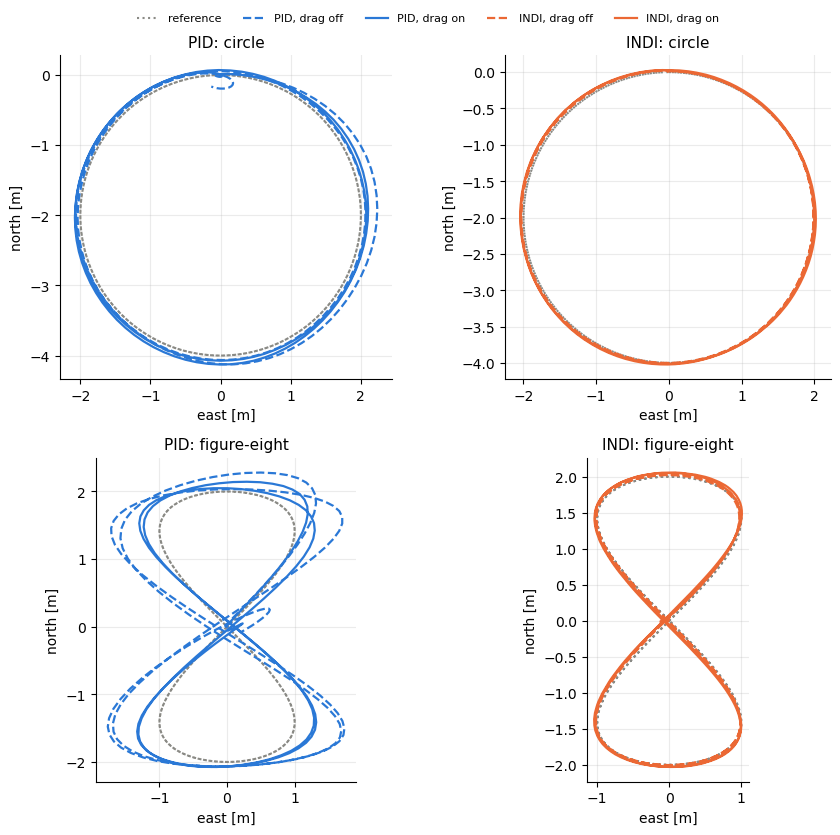

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(9, 8.2))
for row, case in enumerate(CASE_LABELS):
    for col, controller in enumerate(CONTROLLERS):
        ax = axes[row, col]
        base = runs[(controller, "drag off", 1)][case]
        o = base["ref"][0]
        ax.plot(base["ref"][:, 1] - o[1], base["ref"][:, 0] - o[0], color=REF_COLOR, ls=":",
                lw=1.5, label="reference")
        for drag in DRAG:
            r = runs[(controller, drag, 1)][case]
            t0, t1 = r["ref_t"][0], r["ref_t"][-1]
            w = (r["pos_t"] >= t0) & (r["pos_t"] <= t1)
            o = r["ref"][0]
            ax.plot(r["pos"][w, 1] - o[1], r["pos"][w, 0] - o[0], color=COLORS[controller],
                    ls=STYLES[drag], lw=1.6, label=drag)
        ax.set_aspect("equal")
        ax.set_title(f"{controller}: {CASE_LABELS[case]}", fontsize=11)
        ax.set_xlabel("east [m]")
        ax.set_ylabel("north [m]")
handles, labels = [], []
for ax in axes[0]:
    for h, l in zip(*ax.get_legend_handles_labels()):
        name = l if l == "reference" else f"{ax.get_title().split(':')[0]}, {l}"
        if name not in labels:
            handles.append(h)
            labels.append(name)
fig.legend(handles, labels, loc="upper center", ncol=5, fontsize=8, frameon=False,
           bbox_to_anchor=(0.5, 1.02))
fig.tight_layout()

## 4. Why "RMS with drag minus RMS without" is the wrong question

The obvious score is the change in tracking RMS: does drag make the error bigger? The table
below shows it can't answer the question here. For PID on the figure-eight, drag *lowers* the RMS.

In [4]:
def align(r, template):
    # Shift (us) that best overlays this run's received reference on a template run's.
    # Time and position are both measured from each run's own first reference sample, so
    # no model of the trajectory is needed.
    tt, tr = template["ref_t"] - template["ref_t"][0], template["ref"] - template["ref"][0]
    rt, rr = r["ref_t"] - r["ref_t"][0], r["ref"] - r["ref"][0]
    probe = np.linspace(0.0, tt[-1], 400)
    target = np.column_stack([np.interp(probe, tt, tr[:, i]) for i in range(3)])
    best, cost = 0.0, np.inf
    for span, step in ((2e6, 20e3), (40e3, 1e3)):
        for s in best + np.arange(-span, span + step, step):
            here = np.column_stack([np.interp(probe + s, rt, rr[:, i]) for i in range(3)])
            c = np.mean(np.sum((here - target) ** 2, axis=1))
            if c < cost:
                best, cost = s, c
    return best


GRID_DT = 0.1  # s


def error_track(r, template):
    # e(t) = estimated position - received reference, on the template's time grid.
    shift = align(r, template)
    span = template["ref_t"][-1] - template["ref_t"][0]
    grid = r["ref_t"][0] + shift + np.arange(0.0, span, GRID_DT * 1e6)
    lo, hi = max(r["ref_t"][0], r["pos_t"][0]), min(r["ref_t"][-1], r["pos_t"][-1])
    e = np.full((grid.size, 3), np.nan)
    ok = (grid >= lo) & (grid <= hi)
    for i in range(3):
        e[ok, i] = np.interp(grid[ok], r["pos_t"], r["pos"][:, i]) - np.interp(
            grid[ok], r["ref_t"], r["ref"][:, i])
    ref = np.column_stack([np.interp(grid, r["ref_t"], r["ref"][:, i]) for i in range(3)])
    return e, ref


tracks = {}
for (controller, drag, k), r in runs.items():
    for case in CASE_LABELS:
        template = runs[(controller, "drag off", 1)][case]
        tracks[(controller, drag, k, case)] = error_track(r[case], template)


def rms(e):
    return float(np.sqrt(np.nanmean(np.sum(e ** 2, axis=1))))


print(f"{'':22s}" + "".join(f"{CASE_LABELS[c]:>26s}" for c in CASE_LABELS))
for controller in CONTROLLERS:
    for drag in DRAG:
        cells = []
        for case in CASE_LABELS:
            v = [rms(tracks[(controller, drag, k, case)][0]) for k in RUNS]
            cells.append(f"{np.mean(v):.3f} m (runs {min(v):.3f}-{max(v):.3f})")
        print(f"{controller + ', ' + drag:22s}" + "".join(f"{c:>26s}" for c in cells))

                                          circle              figure-eight
PID, drag off         0.181 m (runs 0.178-0.186)0.479 m (runs 0.473-0.482)
PID, drag on          0.137 m (runs 0.135-0.140)0.243 m (runs 0.238-0.254)
INDI, drag off        0.030 m (runs 0.029-0.030)0.047 m (runs 0.040-0.051)
INDI, drag on         0.038 m (runs 0.037-0.039)0.063 m (runs 0.058-0.067)


The reason shows up when the error is split into its **along-track** component, the part along the
reference's direction of travel. Positive means the vehicle is ahead of the reference.

With drag off, the PID-flown vehicle runs *ahead* of the reference, because its velocity
response overshoots on this airframe. On the circle it sits about 0.2 m ahead. Drag pulls it back
through zero to about 0.12 m behind. Both signs of error count the same in an RMS, so the RMS
falls, even though the vehicle has moved about a third of a metre relative to the reference. On
the figure-eight, the overshoot appears as ±0.5 m swings around each lobe. Drag damps those
swings, which lowers the RMS more, while also shifting the error backwards. INDI's along-track
error stays within a few centimetres of zero in both conditions.

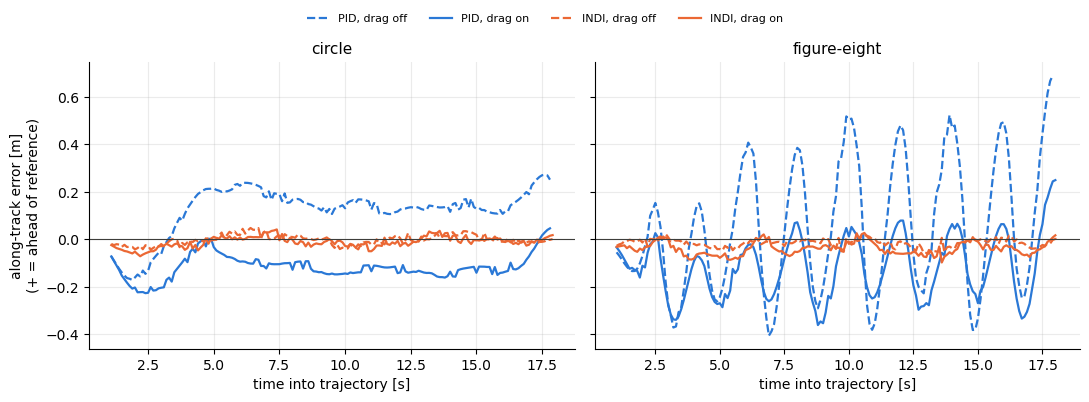

In [5]:
def along_track(e, ref, dt=GRID_DT):
    v = np.gradient(ref[:, :2], dt, axis=0)
    speed = np.linalg.norm(v, axis=1)
    moving = speed > 0.3
    a = np.full(len(e), np.nan)
    a[moving] = np.sum(e[moving, :2] * v[moving] / speed[moving, None], axis=1)
    return a


fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, case in zip(axes, CASE_LABELS):
    for controller in CONTROLLERS:
        for drag in DRAG:
            e, ref = tracks[(controller, drag, 1, case)]
            t = np.arange(len(e)) * GRID_DT
            ax.plot(t, along_track(e, ref), color=COLORS[controller], ls=STYLES[drag], lw=1.6,
                    label=f"{controller}, {drag}")
    ax.axhline(0, color="#3d3d3a", lw=0.8)
    ax.set_title(CASE_LABELS[case], fontsize=11)
    ax.set_xlabel("time into trajectory [s]")
axes[0].set_ylabel("along-track error [m]\n(+ = ahead of reference)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, fontsize=8, frameon=False,
           bbox_to_anchor=(0.5, 1.06))
fig.tight_layout()

## 5. A metric that can't cancel: how far drag moves the error

Instead of comparing two summary numbers, compare the two **error signals** directly. With
$e(t)$ the position error on the reference's time axis, drag's effect on a controller is

$$d(\text{on}, \text{off}) = \sqrt{\operatorname{mean}_t \left\lVert e_\text{on}(t) - e_\text{off}(t) \right\rVert^2}.$$

This is zero only if drag leaves the error signal unchanged, so a shift through zero counts in
full. With three runs per condition there are 3 × 3 = 9 on/off pairs per controller and case.
There are also 2 × 3 = 6 *repeat* pairs: two runs with the same controller and the same drag
setting. The repeats measure run-to-run scatter, which is the noise floor of the comparison.

The pass criterion, fixed before the repeat runs were flown:

1. **Drag measurably affects PID:** every PID on/off distance exceeds every PID repeat distance.
2. **INDI is affected much less:** every INDI on/off distance is below α = 0.5 × the smallest PID
   on/off distance.

Using the worst case on each side keeps the test conservative without assuming any distribution.

In [6]:
def distance(a, b):
    d = np.linalg.norm(a - b, axis=1)
    d = d[np.isfinite(d)]
    return float(np.sqrt(np.mean(d ** 2)))


ALPHA = 0.5
effects = {}
for case in CASE_LABELS:
    for controller in CONTROLLERS:
        on = [tracks[(controller, "drag on", k, case)][0] for k in RUNS]
        off = [tracks[(controller, "drag off", k, case)][0] for k in RUNS]
        effects[(controller, case)] = {
            "cross": [distance(a, b) for a in on for b in off],
            "repeat": [distance(a, b) for group in (on, off) for a, b in combinations(group, 2)],
        }

verdict = {}
for case in CASE_LABELS:
    pid, indi = effects[("PID", case)], effects[("INDI", case)]
    measurable = min(pid["cross"]) > max(pid["repeat"])
    passed = measurable and max(indi["cross"]) < ALPHA * min(pid["cross"])
    verdict[case] = passed
    print(f"{CASE_LABELS[case]:13s} PID effect {min(pid['cross']):.3f}-{max(pid['cross']):.3f} m "
          f"(repeat <= {max(pid['repeat']):.3f}) | INDI effect {min(indi['cross']):.3f}-"
          f"{max(indi['cross']):.3f} m (repeat <= {max(indi['repeat']):.3f}) | "
          f"worst ratio {max(indi['cross']) / min(pid['cross']):.2f} | "
          f"{'PASS' if passed else 'FAIL'}")

circle        PID effect 0.237-0.251 m (repeat <= 0.028) | INDI effect 0.019-0.024 m (repeat <= 0.020) | worst ratio 0.10 | PASS
figure-eight  PID effect 0.326-0.353 m (repeat <= 0.049) | INDI effect 0.021-0.041 m (repeat <= 0.024) | worst ratio 0.13 | PASS


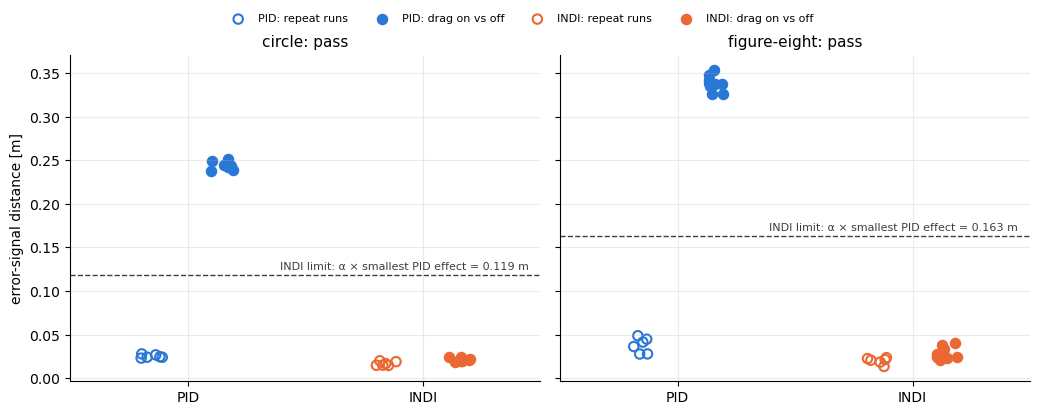

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0), sharey=True)
rng = np.random.default_rng(0)
for ax, case in zip(axes, CASE_LABELS):
    for x0, controller in enumerate(CONTROLLERS):
        e = effects[(controller, case)]
        for dx, kind, marker, fill in ((-0.15, "repeat", "o", "none"),
                                       (0.15, "cross", "o", COLORS[controller])):
            vals = e[kind]
            jitter = rng.uniform(-0.05, 0.05, len(vals))
            ax.scatter(x0 + dx + jitter, vals, s=46, marker=marker, facecolors=fill,
                       edgecolors=COLORS[controller], linewidths=1.5,
                       label=f"{controller}: {'drag on vs off' if kind == 'cross' else 'repeat runs'}")
    limit = ALPHA * min(effects[("PID", case)]["cross"])
    ax.axhline(limit, color="#3d3d3a", ls="--", lw=1)
    ax.annotate(f"INDI limit: α × smallest PID effect = {limit:.3f} m", (1.45, limit),
                xytext=(0, 4), textcoords="offset points", ha="right", fontsize=8, color="#3d3d3a")
    ax.set_xticks([0, 1], list(CONTROLLERS))
    ax.set_xlim(-0.5, 1.5)
    ax.set_title(f"{CASE_LABELS[case]}: {'pass' if verdict[case] else 'fail'}", fontsize=11)
axes[0].set_ylabel("error-signal distance [m]")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, fontsize=8, frameon=False,
           bbox_to_anchor=(0.5, 1.04))
fig.tight_layout()

For PID, the drag effect (filled) is 7–9 times its repeat scatter (hollow), so drag clearly
changes how it flies. For INDI, the drag effect is about the size of its repeat scatter: 0.02 m
on the circle, and at most 0.04 m against 0.02 m of scatter on the figure-eight. On these
trajectories, INDI's response to drag is barely distinguishable from run-to-run variation.

## 6. The same result in time, against the true vehicle position

The simulator logs the vehicle's true position, which gives a check that doesn't depend on the
onboard estimate. For each run, the fit finds the time shift that best overlays the true path on
the received reference. Positive means the vehicle is *ahead* of the reference.

For reference, the onboard estimate itself lags the truth by only 10–35 ms in every run, for both
controllers, so the estimate isn't what makes PID look ahead.

In [8]:
def best_lead_ms(r, signal_t, signal, span_ms=300):
    # s such that signal(t) ~ reference(t + s) + const: s > 0 means signal is ahead.
    t0, t1 = r["ref_t"][0] + 3e6, r["ref_t"][-1] - 3e6  # skip the start/stop ramps
    w = (signal_t >= t0) & (signal_t <= t1)
    best, cost = 0.0, np.inf
    for s in np.arange(-span_ms, span_ms + 1, 2) * 1e3:
        ref = np.column_stack([np.interp(signal_t[w] + s, r["ref_t"], r["ref"][:, i])
                               for i in range(2)])
        d = signal[w, :2] - ref
        c = np.mean(np.sum((d - d.mean(axis=0)) ** 2, axis=1))
        if c < cost:
            best, cost = s, c
    return best / 1e3


leads = {}
for (controller, drag, k), r in runs.items():
    for case in CASE_LABELS:
        c = r[case]
        leads[(controller, drag, k, case)] = {
            "truth": best_lead_ms(c, c["truth_t"], c["truth"]),
            "estimate": best_lead_ms(c, c["pos_t"], c["pos"]),
        }
for controller in CONTROLLERS:
    for case in CASE_LABELS:
        off = [leads[(controller, "drag off", k, case)]["truth"] for k in RUNS]
        on = [leads[(controller, "drag on", k, case)]["truth"] for k in RUNS]
        lag = [leads[(controller, d, k, case)]["truth"] - leads[(controller, d, k, case)]["estimate"]
               for d in DRAG for k in RUNS]
        print(f"{controller:4s} {CASE_LABELS[case]:13s} truth lead: drag off {np.mean(off):+5.0f} ms, "
              f"drag on {np.mean(on):+5.0f} ms -> drag shifts it {np.mean(on) - np.mean(off):+5.0f} ms"
              f"   (estimate lags truth {np.mean(lag):3.0f} ms)")

PID  circle        truth lead: drag off  +127 ms, drag on   -47 ms -> drag shifts it  -174 ms   (estimate lags truth  25 ms)
PID  figure-eight  truth lead: drag off   +33 ms, drag on   -76 ms -> drag shifts it  -109 ms   (estimate lags truth  13 ms)
INDI circle        truth lead: drag off   +26 ms, drag on   +22 ms -> drag shifts it    -4 ms   (estimate lags truth  28 ms)
INDI figure-eight  truth lead: drag off    +1 ms, drag on   -11 ms -> drag shifts it   -12 ms   (estimate lags truth  16 ms)


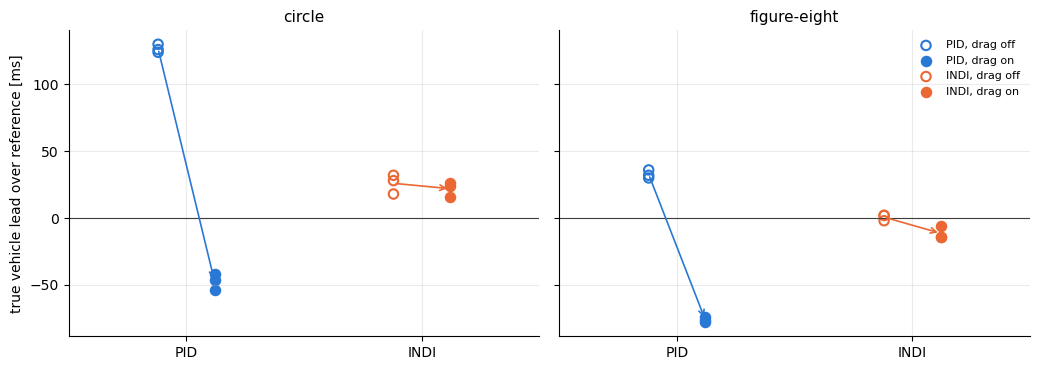

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True)
for ax, case in zip(axes, CASE_LABELS):
    for x0, controller in enumerate(CONTROLLERS):
        for dx, drag in ((-0.12, "drag off"), (0.12, "drag on")):
            vals = [leads[(controller, drag, k, case)]["truth"] for k in RUNS]
            ax.scatter(np.full(len(vals), x0 + dx), vals, s=46,
                       facecolors="none" if drag == "drag off" else COLORS[controller],
                       edgecolors=COLORS[controller], linewidths=1.5, label=f"{controller}, {drag}")
        means = [np.mean([leads[(controller, d, k, case)]["truth"] for k in RUNS]) for d in DRAG]
        ax.annotate("", xy=(x0 + 0.12, means[1]), xytext=(x0 - 0.12, means[0]),
                    arrowprops=dict(arrowstyle="->", color=COLORS[controller], lw=1.2))
    ax.axhline(0, color="#3d3d3a", lw=0.8)
    ax.set_xticks([0, 1], list(CONTROLLERS))
    ax.set_xlim(-0.5, 1.5)
    ax.set_title(CASE_LABELS[case], fontsize=11)
axes[0].set_ylabel("true vehicle lead over reference [ms]")
axes[1].legend(fontsize=8, frameon=False, loc="upper right")
fig.tight_layout()

Drag delays the PID-flown vehicle by 110–175 ms, taking it from ahead of the reference to behind
it. The INDI vehicle stays within about ±30 ms of the reference, and drag moves it by 4–12 ms.

## 7. Cross-check against the automated scoring

The same runs were also scored by an independent implementation, which aligns each run against a
model of the trajectory rather than against another run. Its drag-effect ranges should agree with
section 5 to within about a centimetre. The PID runs differ most, because aligning them against
each other rather than against a model picks up a little more of their run-to-run variation.

In [10]:
gate = json.loads((DATA / "gate.json").read_text())
worst = 0.0
for row in gate["cases"]:
    for controller, key in (("PID", "stock_effect_m"), ("INDI", "custom_effect_m")):
        ours = effects[(controller, row["case"])]["cross"]
        diff = max(abs(min(ours) - row[key][0]), abs(max(ours) - row[key][1]))
        worst = max(worst, diff)
        print(f"{CASE_LABELS[row['case']]:13s} {controller:4s} here {min(ours):.3f}-{max(ours):.3f} m"
              f"  automated {row[key][0]:.3f}-{row[key][1]:.3f} m")
print(f"largest difference: {worst * 1000:.1f} mm; automated verdict passed={gate['passed']}")

circle        PID  here 0.237-0.251 m  automated 0.232-0.260 m
circle        INDI here 0.019-0.024 m  automated 0.019-0.024 m
figure-eight  PID  here 0.326-0.353 m  automated 0.328-0.341 m
figure-eight  INDI here 0.021-0.041 m  automated 0.019-0.040 m
largest difference: 11.8 mm; automated verdict passed=True


## Takeaways

1. **INDI rejects drag; PID absorbs it as error.** On fast trajectories where drag is about 45%
   of the centripetal force, drag changes the PID vehicle's error by 0.24–0.35 m and delays it by
   110–175 ms. INDI's change is near its run-to-run noise floor (0.02–0.04 m and 4–12 ms). That is
   what measuring acceleration, rather than waiting for position error, predicts.
2. **Compare error signals, not error sizes.** A controller that overshoots without a disturbance
   can get a *smaller* RMS once the disturbance pushes its error through zero. The distance
   between error signals has no such blind spot.
3. **Repeat each condition.** Without repeats there is no way to tell a small effect from
   run-to-run scatter. Here, the claim that INDI is barely affected only holds *because* its drag
   effect can be compared with its own scatter.

**Limits.** The drag coefficients are illustrative, not identified from a real vehicle, so the
result is about the *shape* of the comparison, not absolute numbers. The PID runs use the
autopilot's default tune, which overshoots on this simulated airframe. A better-damped tune would
lower its RMS, but drag would still move its error by a comparable amount. Only the two fast
trajectories were flown; slower ones see less drag.